In [1]:
#Here, we define
import numpy as np
import math
import matplotlib.pyplot as plt
from sympy import *
import sympy
from sklearn.linear_model import LinearRegression
from sympy import re, im, I, E, symbols, exp
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize
import time

import tensorflow as tf

import glob

from tensorflow.keras.layers import Dense,Flatten,Cropping1D, Concatenate, MaxPooling1D, Dropout, Reshape, Conv1D, BatchNormalization, Activation, AveragePooling1D, GlobalAveragePooling1D, Lambda, Input, Concatenate, Add, UpSampling1D, Multiply
from tensorflow.keras.models import Model
from tensorflow.keras import losses
from tensorflow.keras.losses import Hinge
from tensorflow.keras import backend as K
from tensorflow.keras.losses import binary_crossentropy, categorical_crossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard, ReduceLROnPlateau,LearningRateScheduler
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.callbacks import Callback
from tensorflow.keras.models import Sequential
from sklearn.metrics import cohen_kappa_score, f1_score
from sklearn.model_selection import KFold, train_test_split

from scipy.special import legendre
from scipy.special import chebyt, chebyu



import numpy as np
from scipy.special import pro_ang1
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


In [2]:
# Definimos el valor de K

def Archit(K):

# We create an arrange with K values
    Array = np.arange(1, K[0] + 1)

# e create an arrange of the form (j, K * j)
    Lay_x_Neu = np.column_stack((Array, K[1] * Array))

    return Lay_x_Neu

In [3]:
#Number of samples and parameters

max_order_slep = 35 # increase to 20 or more eventually

Nsamples = np.logspace(1, np.log10(10000), 10).astype(int)
Ntest= 1000

#Para_slep = np.linspace(1, max_order_slep+1, 10).astype(int)
Para_slep= [10]
total_runs = 20

cVal = [3,3.5,4,4.5,5]

In [4]:
Nsamples

array([   10,    21,    46,   100,   215,   464,  1000,  2154,  4641,
       10000])

In [5]:
# Define the samples
def samps(t):

    Values = np.random.uniform(-1, 1, int(t[0]) if isinstance(t, (list, np.ndarray)) else int(t))


    #Ordenar os valores de mayor a menor
    #OValues = np.sort(Values)  # [::-1] invierte el orden

    return Values

In [6]:
#This is the function that we approximate
def funct(x):
    # t is the variable
    g = np.exp(-0.5*(x)**2)


    return g

In [7]:
#Returns the Slepian basis function

def NorSlep(j, c):
    b = 0 # Alpha parameter for the PSAF
    theta = np.linspace(-1, 1, 200)

    psaf_values = pro_ang1(b, j, c, theta)
    psaf_values = psaf_values[0]

    psaf_values = psaf_values[1:199]
    l2_norm = np.linalg.norm(psaf_values)/np.sqrt(len(theta)-1)


    return l2_norm



In [8]:
#Compute the PSWF with j and c at the value x.

def PSWF(x, j, c):

    b = 0 # Alpha parameter for the PSAF

    # Calculate the PSAF values for the two modes
    psaf_values = pro_ang1(b, j, c, x)
    psaf_values = psaf_values[0]



    l2_norm = norms_[j]

    return psaf_values/l2_norm

In [9]:
#We know create the matrix for the ls approximation

def Matrix(samp, ordens, c):

    A= np.zeros((len(samp), ordens))
    #We create the matrix for the least square
    for j in range(ordens):
        for k in range(len(samp)):
            A[k,j]= PSWF(samp[k], j, c)

    return A

In [27]:
MSE_slep = np.zeros(
    [len(cVal), len(Para_slep), len(Nsamples), total_runs]
)


start_time = time.time()

total_iterations = len(cVal)*total_runs*len(Para_slep)*len(Nsamples)

counter = 0


for ic,c in enumerate(cVal):


    # Compute norms for this c
    norms_ = np.zeros([Para_slep[-1]])

    for k in range(Para_slep[-1]):
        norms_[k] = NorSlep(k,c)



    for run in range(total_runs):

        # Generate training data

        SamSet_ = samps(Nsamples[-1])

        y_ = funct(SamSet_)


        # Slepian matrix with this c

        A_ = Matrix(
            SamSet_,
            Para_slep[-1],
            c
        )


        # Test data

        TestSet = samps(Ntest)

        Values_test = funct(TestSet)


        # Slepian test matrix

        test_PSWF_matrix_ = np.array(
            [
                [
                    PSWF(t,i,c)
                    for i in range(Para_slep[-1])
                ]
                for t in TestSet
            ]
        )



        for orde in range(len(Para_slep)):


            for k in range(len(Nsamples)):


                A_s = A_[:Nsamples[k], :Para_slep[orde]]

                y = y_[:Nsamples[k]]


                test_PSWF_matrix = test_PSWF_matrix_[:, :Para_slep[orde]]



                # Least squares

                x = np.linalg.lstsq(
                    A_s,
                    y,
                    rcond=None
                )[0]


                linear_combination_t = test_PSWF_matrix @ x


                Err = np.linalg.norm(
                    linear_combination_t - Values_test
                ) / np.sqrt(Ntest)



                MSE_slep[ic,orde,k,run] = Err



                counter += 1

                now_time = time.time()


                print(
                    "c = " + str(c) +
                    ", Error: " + str(Err) +
                    ", Progress: " +
                    format(100*counter/total_iterations,'.2f') +
                    "%" +
                    ", approx. " +
                    format(
                        (total_iterations-counter)*
                        (now_time-start_time)/counter,
                        '.1f'
                    ) +
                    " seconds remaining."
                )

c = 3, Error: 2.464529632235171e-07, Progress: 0.10%, approx. 3327.2 seconds remaining.
c = 3, Error: 4.547040358079807e-07, Progress: 0.20%, approx. 1662.1 seconds remaining.
c = 3, Error: 3.5686501219268035e-08, Progress: 0.30%, approx. 1107.0 seconds remaining.
c = 3, Error: 2.0824360252570386e-08, Progress: 0.40%, approx. 829.4 seconds remaining.
c = 3, Error: 1.7703139198532338e-08, Progress: 0.50%, approx. 662.9 seconds remaining.
c = 3, Error: 1.7530215295442853e-08, Progress: 0.60%, approx. 551.9 seconds remaining.
c = 3, Error: 1.7674881710112155e-08, Progress: 0.70%, approx. 472.6 seconds remaining.
c = 3, Error: 1.7540556698921066e-08, Progress: 0.80%, approx. 413.2 seconds remaining.
c = 3, Error: 1.742702101972257e-08, Progress: 0.90%, approx. 367.0 seconds remaining.
c = 3, Error: 1.737054167074615e-08, Progress: 1.00%, approx. 330.1 seconds remaining.
c = 3, Error: 1.7115472772220447e-07, Progress: 1.10%, approx. 553.0 seconds remaining.
c = 3, Error: 2.55723002068403e-0

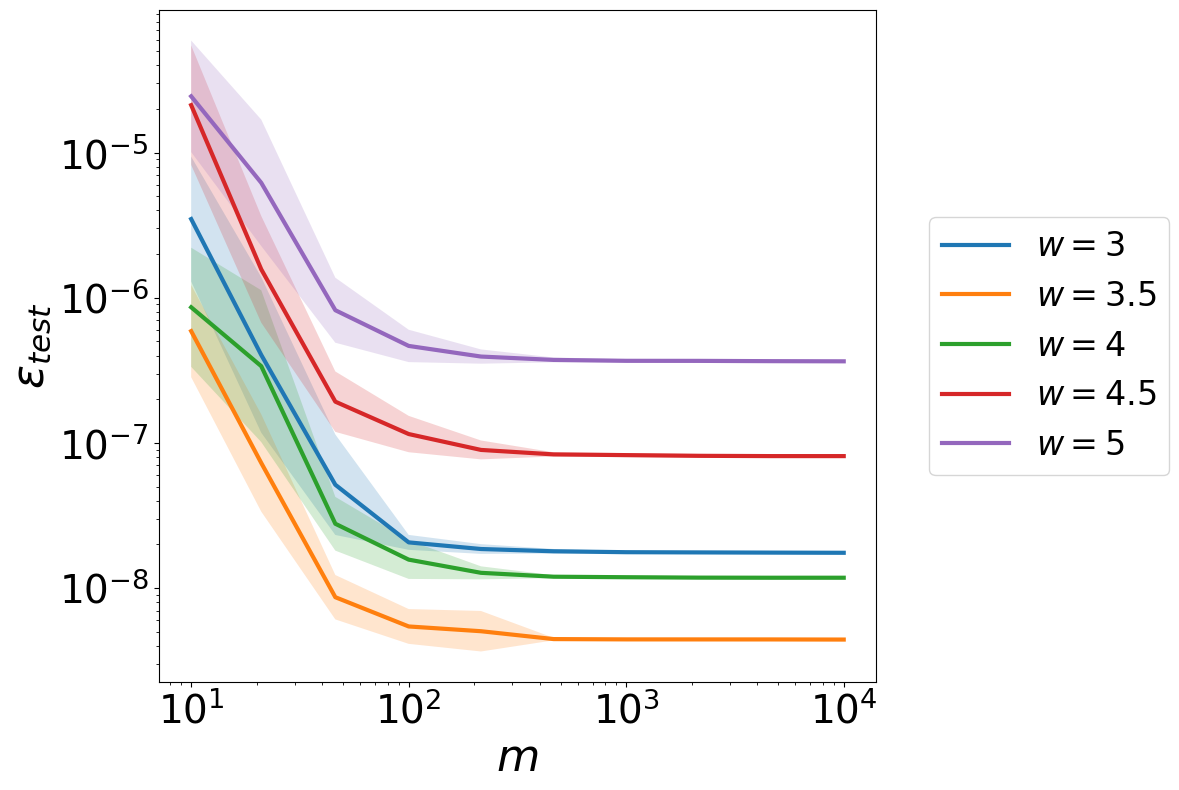

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
from google.colab import files

plt.figure(figsize=(12,8))


for ic,c in enumerate(cVal):

    results_mean = np.mean(MSE_slep[ic], axis=2)
    results_lower = np.std(MSE_slep[ic], axis=2)/results_mean


    plt.loglog(
        Nsamples,
        results_mean[0,:],
        linewidth=3,
        label=f"$w={c}$"
    )

    plt.fill_between(
        Nsamples,
        results_mean[0,:]/(1+results_lower[0,:]),
        results_mean[0,:]*(1+results_lower[0,:]),
        alpha=0.2
    )


plt.xlabel(r"$m$",fontsize=32)
plt.ylabel(r"$\epsilon_{test}$",fontsize=32)

plt.tick_params(axis='both',labelsize=28)

plt.legend(
    fontsize=24,
    bbox_to_anchor=(1.05,0.5),
    loc="center left"
)

plt.tight_layout()

plt.savefig("varying_bandwidth.pdf")

plt.show()


files.download("varying_bandwidth.pdf")



In [29]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
results_mean_leg-results_mean_cheby

In [ ]:
results_mean - results_mean_leg

In [ ]:
results_mean - results_mean_cheby


In [ ]:
print(test_PSWF_matrix.shape)


In [ ]:
print(test_PSWF_matrix_.shape)
